# Prerequisites
- XGBoost Regressor
- Gradient Boosting Classifier
- Log of odds (taught in the Gradient Boosting Classifier notebook)
<hr>

- Lets take the below toy dataset to study XGBoost classifier.

1 feature: cgpa
target: placed (0 or 1)

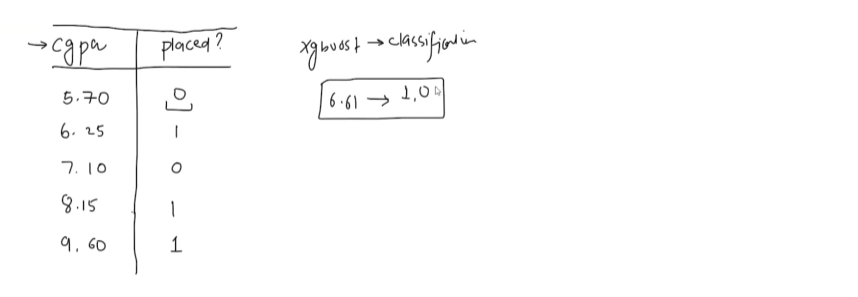

# Overview of XGBoost for Classification

- As XGBoost is optimized verision of Gradient Boosting, the general flow of XGBoost is same as Gradient Boosting. 

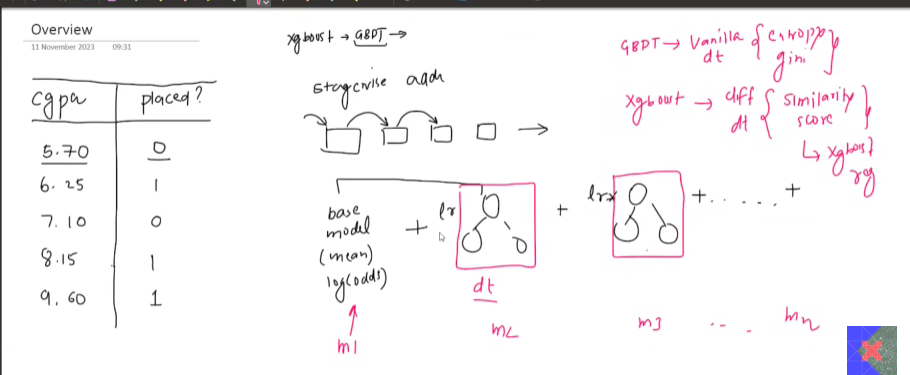

- The major difference between XGBoost and Gradient Boosting is that in XGBoost, we will build the decision tree using a Similarity Score and Gain in Similarity Score instead of using Entropy/Gini Impurity and Information Gain as we did in Gradient Boosting.

# Step-by-Step Implementation of XGBoost for Classification

## Stage 1: The first model will be log of odds of the target variable.

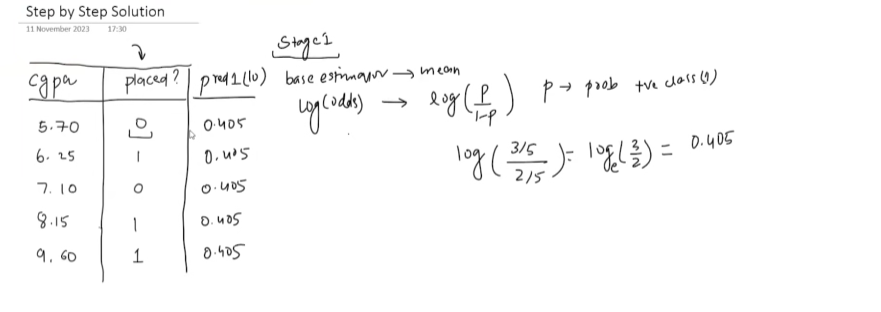

- Now for stage 1 prediction we need to convert the log of odds to probability using the below formula:

$$ p = \frac{1}{1 + e^{-log\_odds}} $$

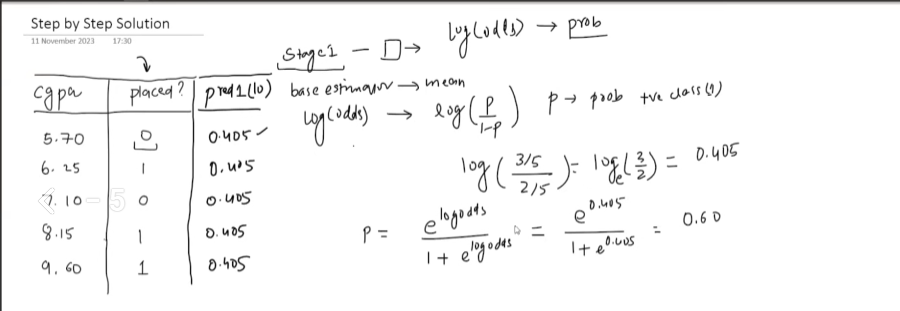

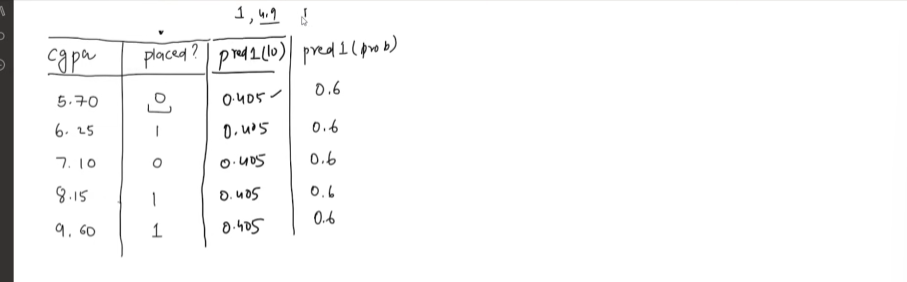

- So, the predicted probability of the first model is 0.6,hence the predicted class is 1 (we are using 0.5 as threshold).

- Now calculate the pseudo residuals for the first model

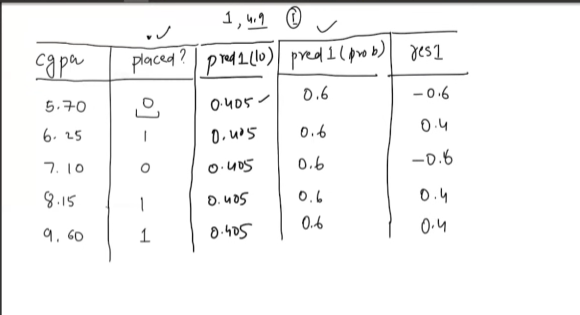

## Stage 2: The second model will be a decision tree 

- The **regression decision tree** (as we are predicting pseudo residuals which are continuous values) will be built using the pseudo residuals as the target variable and the feature cgpa as the input variable.

- Now this decision tree will be built using the Similarity Score and Gain in Similarity Score as we did in the XGBoost for Regression notebook.

### Stage 2.1: Make leaf node of the residuals

- Find the similarity score for the leaf node of the residuals using the below formula:

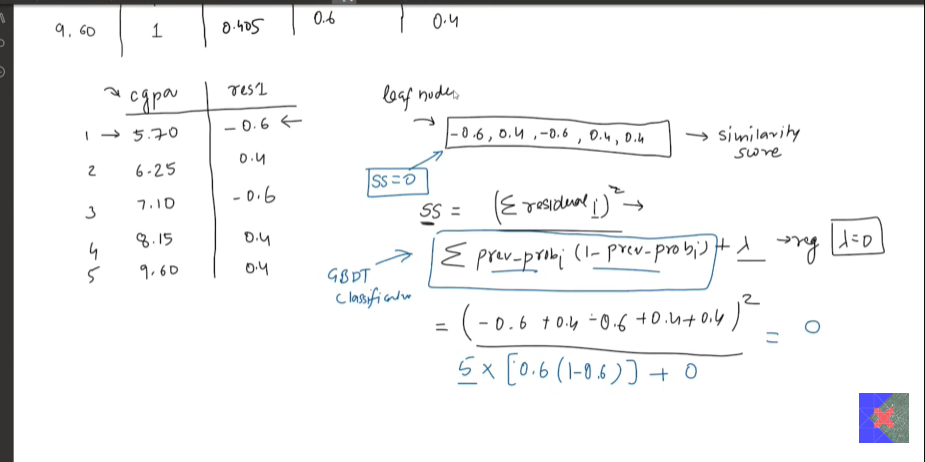

### Stage 2.2: Split the leaf node into two child nodes

- Now we will split the leaf node into two child nodes using the feature cgpa and find the similarity score for each child node and our goal is to find the split which gives us the highest gain in similarity score.

- So, sort the data based on the feature cgpa and find the similarity score for each possible split and then find the gain in similarity score for each possible split. And then choose the split which gives us the highest gain in similarity score.

- Below are the 4 splitting conditions for the feature cgpa:

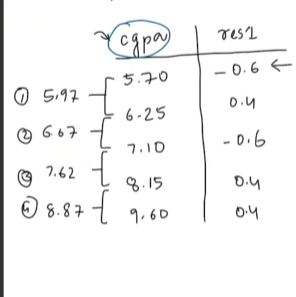

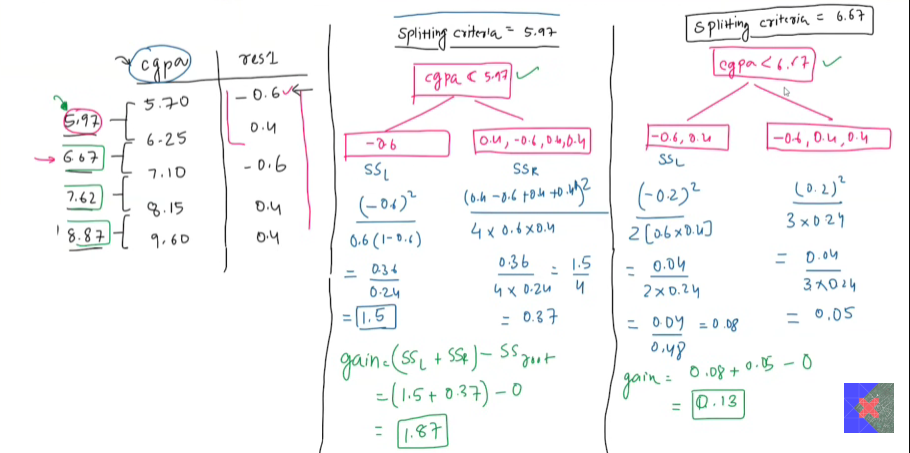

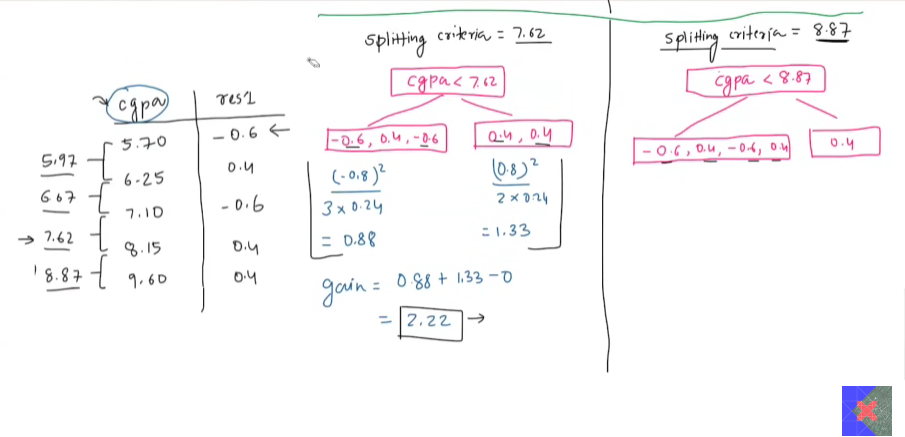

- So on calculating , splitting criteria (cgpa <= 7.62) is giving us the highest gain in similarity score, hence we will choose this split and split the leaf node into two child nodes.

- Now we can further split the child nodes into two child nodes and keep on splitting until we reach the maximum depth of the tree or until we reach the minimum number of samples in a leaf node. 

- But here we will stop at depth 1 and find the terminal regions of the decision tree to avoid overfitting.

- So final stage 2 model:

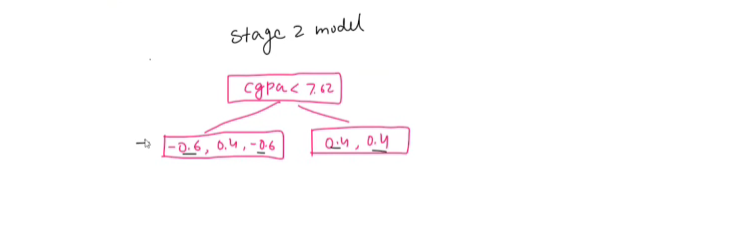

- Now for calculating stage 2 output generally we would use the mean of the residuals in each terminal region, but since we are doing classification, we will use the log odds so we need to convert the residuals into log odds using the following formula:

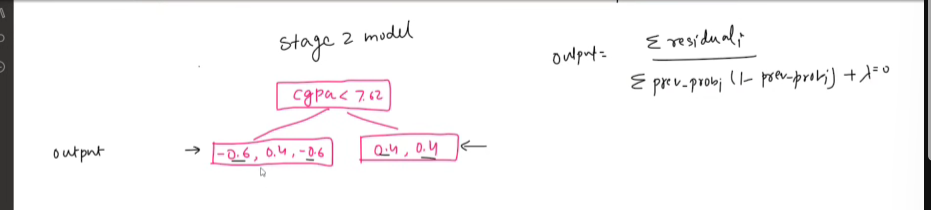

(we are taking $\lambda = 0$ (no regularization))

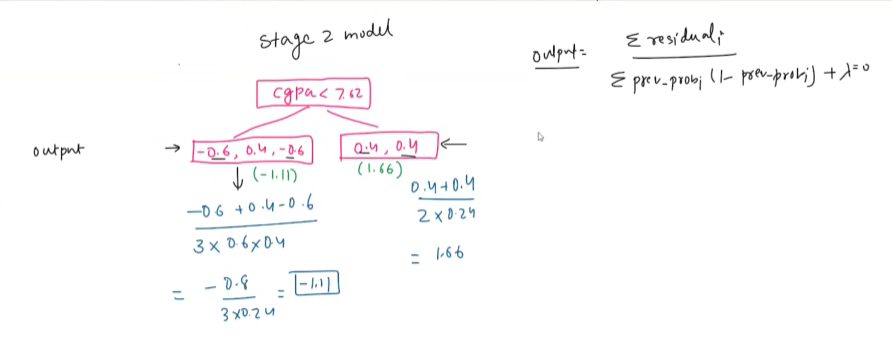

### Stage 2.3: Calculating preciction using stage 1 and stage 2 models combined

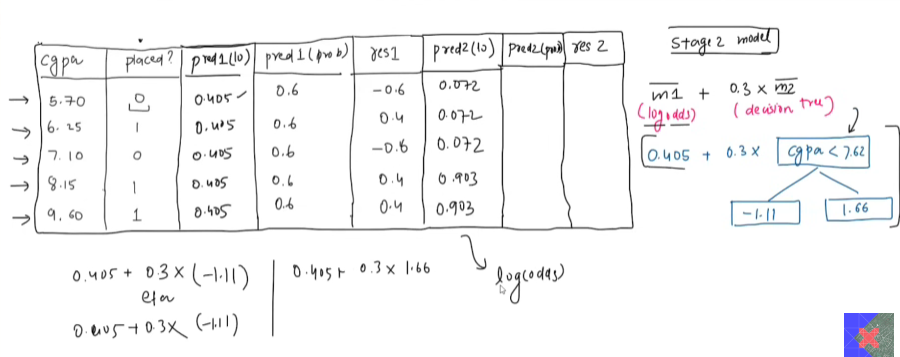

- Now we can convert the log odds to probability using the below formula:

$$ p = \frac{1}{1 + e^{-log\_odds}} $$

- And, res2 = placed - pred2_prob

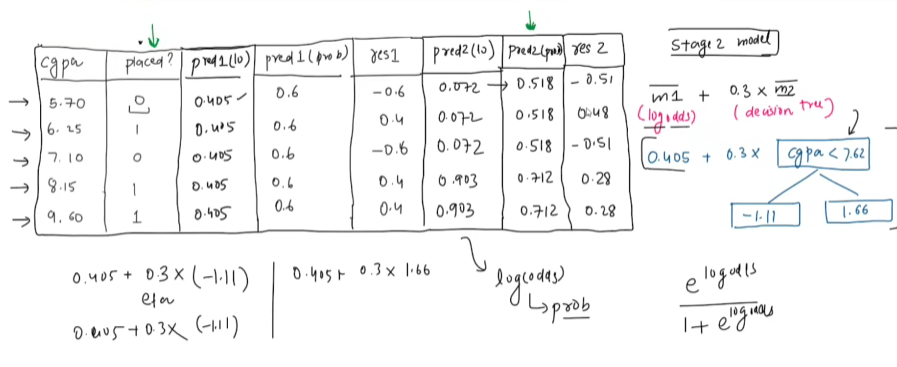

- SO you can see that the pseudo residuals are decreasing after each stage and the predicted probability is increasing after each stage. Hence, the model is improving after each stage.

## Stage 3: The third model will be a decision tree

- Use cgpa as the input variable and res2 as the target variable to build the decision tree.
- And repeat the same steps as we did in stage 2 to build the decision tree and find the terminal regions of the decision tree

- And similarly we can keep on adding more stages to the model until we make residuals as close to 0 as possible 

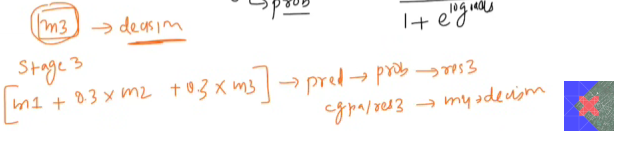